In [ ]:
import sys, re, joblib, cv2
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

sys.path.append("../src")
from ocr_module import ocr_image

model = joblib.load("../src/leaklens_logreg.joblib")
CLASSES = list(model.classes_)          # ['credential','email','phone','safe','url_internal']
SAFE_IDX = CLASSES.index("safe")

img = cv2.imread("../data/screenshots/real_01.png")
items = ocr_image(img)
print(len(items), "pieces found")

Using CPU. Note: This module is much faster with a GPU.
c:\Users\Victus\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\ao\nn\quantized\dynamic\modules\rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\quantized\Quantizer.cpp:116.)
  w_ih = torch.quantize_per_tensor(
c:\Users\Victus\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


164 pieces found


In [ ]:
def classify_items(items, threshold=0.80):
    if not items:
        return items
    probs = model.predict_proba([it["text"] for it in items])
    for it, p in zip(items, probs):
        p_sensitive = 1 - p[SAFE_IDX]
        others = p.copy(); others[SAFE_IDX] = -1
        best = CLASSES[int(np.argmax(others))]
        if p_sensitive >= threshold:
            it["label"], it["prob"] = best, round(float(p_sensitive), 3)
        else:
            it["label"], it["prob"] = "safe", round(float(1 - p_sensitive), 3)
    return items

items = classify_items(items, threshold=0.80)
flagged = [it for it in items if it["label"] != "safe"]
print(len(flagged), "flagged out of", len(items))
pd.DataFrame(flagged)[["text", "label", "prob", "conf"]].sort_values("prob", ascending=False)

43 flagged out of 164


,text,label,prob,conf
6,Phone: (555) 867-5309,phone,0.999,0.978
2,Due: 2024-05-25,phone,0.996,0.942
11,Account #: ACCT-445566,credential,0.996,0.683
28,Phone:,phone,0.996,0.998
30,2024-04-26,phone,0.996,0.999
37,2024-04-16,phone,0.996,0.707
36,2024-04-16,phone,0.996,0.595
18,2024-04-16,phone,0.996,0.768
23,2024-05-16 02.00 PM,phone,0.996,0.881
16,2024-04-15,phone,0.995,0.732


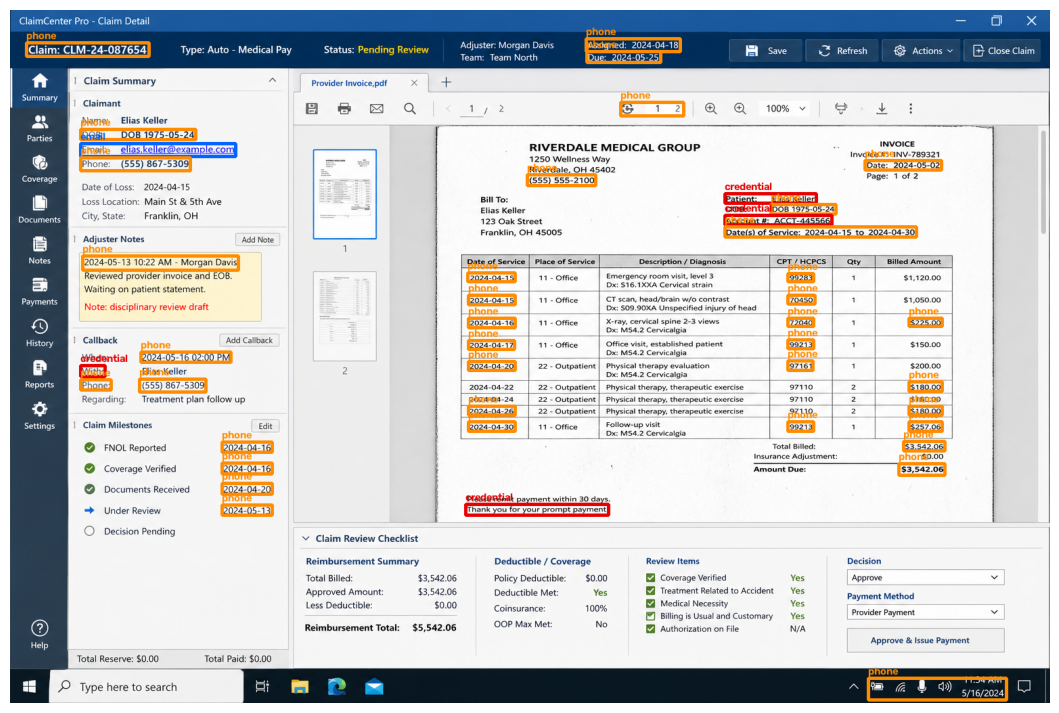

In [ ]:
COLORS = {            # BGR colors
    "email": (255, 100, 0),         # blue
    "phone": (0, 140, 255),         # orange
    "url_internal": (200, 0, 160),  # purple
    "credential": (0, 0, 230),      # red
}

def highlight(img, items):
    out = img.copy()
    for it in items:
        if it["label"] == "safe":
            continue
        c = COLORS[it["label"]]
        x, y, w, h = it["x"], it["y"], it["w"], it["h"]
        cv2.rectangle(out, (x, y), (x + w, y + h), c, 3)
        cv2.putText(out, it["label"], (x, max(y - 5, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, c, 2)
    return out

result = highlight(img, items)
cv2.imwrite("../report/figures/highlight_real_01.png", result)
plt.figure(figsize=(14, 9))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.axis("off"); plt.show()

In [ ]:
raw_items = ocr_image(img)
for th in [0.5, 0.7, 0.8, 0.9, 0.95]:
    tmp = classify_items([dict(i) for i in raw_items], threshold=th)
    n = sum(1 for i in tmp if i["label"] != "safe")
    print(f"threshold {th}: {n} flagged")

c:\Users\Victus\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


threshold 0.5: 66 flagged
threshold 0.7: 53 flagged
threshold 0.8: 43 flagged
threshold 0.9: 36 flagged
threshold 0.95: 26 flagged


In [ ]:
raw_items = ocr_image(img)
for th in [0.5, 0.7, 0.8, 0.9, 0.95]:
    tmp = classify_items([dict(i) for i in raw_items], threshold=th)
    n = sum(1 for i in tmp if i["label"] != "safe")
    print(f"threshold {th}: {n} flagged")

c:\Users\Victus\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


threshold 0.5: 66 flagged
threshold 0.7: 53 flagged
threshold 0.8: 43 flagged
threshold 0.9: 36 flagged
threshold 0.95: 26 flagged


In [ ]:
%%writefile ../src/detector.py
import joblib, cv2, numpy as np
from ocr_module import ocr_image

_model = None
COLORS = {"email": (255, 100, 0), "phone": (0, 140, 255),
          "url_internal": (200, 0, 160), "credential": (0, 0, 230)}

def get_model(path="../src/leaklens_logreg.joblib"):
    global _model
    if _model is None:
        _model = joblib.load(path)
    return _model

def detect(img, threshold=0.80, model_path="../src/leaklens_logreg.joblib"):
    model = get_model(model_path)
    classes = list(model.classes_)
    safe_idx = classes.index("safe")
    items = ocr_image(img)
    if not items:
        return items
    probs = model.predict_proba([i["text"] for i in items])
    for it, p in zip(items, probs):
        p_sens = 1 - p[safe_idx]
        others = p.copy(); others[safe_idx] = -1
        if p_sens >= threshold:
            it["label"], it["prob"] = classes[int(np.argmax(others))], round(float(p_sens), 3)
        else:
            it["label"], it["prob"] = "safe", round(float(1 - p_sens), 3)
    return items

def highlight(img, items):
    out = img.copy()
    for it in items:
        if it["label"] == "safe":
            continue
        c = COLORS[it["label"]]
        x, y, w, h = it["x"], it["y"], it["w"], it["h"]
        cv2.rectangle(out, (x, y), (x + w, y + h), c, 3)
        cv2.putText(out, it["label"], (x, max(y - 5, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, c, 2)
    return out

Writing ../src/detector.py


In [ ]:
import sys, os, importlib, difflib
import cv2
import pandas as pd
import matplotlib.pyplot as plt
sys.path.append("../src")
import ocr_module, detector
importlib.reload(ocr_module); importlib.reload(detector)
from ocr_module import ocr_image
from detector import detect, highlight

SHOTS = "../data/screenshots/"
names = ["test_01_env_file.png", "test_02_chat.png",
         "test_03_code_editor.png", "test_04_safe_control.png"]
images, ocr_cache = {}, {}
for n in names:
    images[n] = cv2.imread(SHOTS + n)
    assert images[n] is not None, f"Cannot find {SHOTS + n}"
    ocr_cache[n] = ocr_image(images[n])
    print(n, "->", len(ocr_cache[n]), "OCR pieces")

Using CPU. Note: This module is much faster with a GPU.
c:\Users\Victus\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


test_01_env_file.png -> 12 OCR pieces
test_02_chat.png -> 10 OCR pieces
test_03_code_editor.png -> 11 OCR pieces
test_04_safe_control.png -> 8 OCR pieces


In [ ]:
n = names[0]
dets, items = detect(items=ocr_cache[n])
print("OCR text  ->  cleaned text")
for it in items:
    print(f'  ocr={it["conf"]:.2f} | {it["text"]!r}  ->  {it["norm"]!r}')
df = pd.DataFrame(dets)
display(df[["label", "prob", "source", "text", "line"]] if len(df) else "nothing flagged")

TypeError: detect() got an unexpected keyword argument 'items'